# Does synthetic data help? A Control Experiment

## 1. Introduction

### 1.1 The problem

The 200k model from `07_modeling_cmu(+synthetic200k)` trains on **128,078 real rows plus 71,922 synthetic diabetes rows**, and scores ROC AUC ≈ 0.802 and recall ≈ 0.849 on the shared test set. That number alone cannot tell us **why** the model does well, because two things changed at once between 07 and the earlier 70k model:

1. **class weighting and real-data volume** (07 adds 100,000 real no-diabetes rows the 70k model did not have), and
2. **the 71,922 synthetic diabetes rows** themselves.

The 70k and 200k models differ in both, so any performance difference between them is unattributable. This is exactly the same shape of problem as the feature-parity issue (#2): change one thing at a time, or the result has no cause.

### 1.2 The fix: a third model with only the synthetic rows removed

We train a **control model** that keeps every real row the 200k model has and **drops only the synthetic rows**. Everything else — features, pipeline, hyperparameters, seed, fold construction, threshold rule, test set — is identical.

| | Treatment (07) | Control (this notebook) | Δ |
|---|---|---|---|
| Real no-diabetes | 100,000 | 100,000 (same sample, seed 42) | 0 |
| Real diabetes | all real | all real (identical) | 0 |
| Synthetic diabetes | 71,922 | **0** | **−71,922** |
| Total rows | 200,000 | 128,078 | −71,922 |
| Features | `shared_16_features` | `shared_16_features` | — |
| Class weighting | balanced | balanced | — |
| Threshold rule | OOF quantile, target recall 0.85 | **identical** | — |
| Test set | `diabetes_model_test` (14,039) | **identical** | — |

Because only the synthetic component changes, any difference in the results is attributable to synthetic data:

- **`200k − control`** = the synthetic-data effect (what this notebook measures)
- **`control − 70k`** = the real-data + class-weighting effect (not measured here, but attributable in the writeup once the notebook above has been run)

### 1.3 What we expect

- **If `|ΔAUC| < 0.01` and `|Δrecall| < 0.01`** (within the noise band on 14k rows), synthetic data added nothing on this split. The 07 gain comes from class weighting and real-data volume. This is a valid, honest finding and should be reported exactly that way.
- **If `|ΔAUC| ≥ 0.01` or `|Δrecall| ≥ 0.01`**, synthetic data changed the holdout result, and the sign of Δ tells us whether it helped or hurt.

Either way both models are reported side by side. The goal is to **attribute** the 07 result, not to prove that synthetic data wins.

### 1.4 What this notebook does NOT do

- It does not retrain the 70k model, so `control − 70k` cannot be measured here.
- It does not evaluate synthetic data in general, only **the specific `generate_synthetic` configuration 07 used**.
- It does not produce a production model. The control lives in memory and is not saved to `application/models/`.

**Source tables:** `diabetes_final_clean_merged_unbalanced` (real pool), `diabetes_model_test` (holdout). **Source model:** `application/models/logreg_200k.joblib`.

In [31]:
# Standard library: paths, module loading, filesystem checks
import os
import importlib.util
from pathlib import Path

# pandas / numpy: data handling and calculations
import numpy as np
import pandas as pd

# joblib: load the 200k treatment bundle
import joblib

# scikit-learn: pipeline, cross-validation, threshold rule, metrics
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score

# SQLAlchemy: connection between Python and the MariaDB database
from sqlalchemy import create_engine

# matplotlib / seaborn: charts
import matplotlib.pyplot as plt
import seaborn as sns

# Project root, so relative paths resolve
os.chdir(r"c:\Users\PLP\Documents\dsf-final-project-setc")

# Our helper file in 09_utils
_spec = importlib.util.spec_from_file_location(
    "synth_utils", Path("notebooks/09_utils/synth_utils.py"))
synth_utils = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(synth_utils)
FEATURES, TARGET = synth_utils.FEATURES, synth_utils.TARGET

# Guard: the treatment bundle must exist before we start
TREAT_PATH = Path("application/models/logreg_200k.joblib")
assert TREAT_PATH.exists(), (
    f"{TREAT_PATH} is missing. Run 07_modeling_cmu(+synthetic200k)/02_train.ipynb first."
)

# Fixed settings, matching 07_modeling_cmu(+synthetic200k)
RANDOM_STATE  = 42
N_PER_CLASS   = 100_000          # rows per class in the 07 training set
TARGET_RECALL = 0.85             # the threshold rule used in 07
N_FOLDS       = 5
NOISE_BAND    = 0.01             # |Δ| below this is treated as within noise on 14k test rows

# Display settings, matching 03_eda
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Features used by the 200k model: {len(FEATURES)}")
print(f"Treatment bundle present: {TREAT_PATH} ({TREAT_PATH.stat().st_size:,} bytes)")

Features used by the 200k model: 21
Treatment bundle present: application\models\logreg_200k.joblib (3,863 bytes)


## 2. Load the Real Rows and the Holdout Set

The 07 notebook drew its real negatives from `diabetes_final_clean_merged_unbalanced`, sampled 100,000 no-diabetes rows with `random_state=42`, kept every real diabetes row, and dropped any pool row that also appears in the test set. We reproduce each of these steps exactly, so the control uses the **same real pool** the treatment started from.

If any of those steps drifted between the two notebooks, the comparison would mix "synthetic removed" with "different real rows", and we would be back to the same attribution problem.

**Source tables:** `diabetes_final_clean_merged_unbalanced` (pool), `diabetes_model_test` (holdout).

In [32]:
# Load the pool from the database; fall back to the CSV export if the DB is down
try:
    engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")
    df     = pd.read_sql("SELECT * FROM diabetes_final_clean_merged_unbalanced", con=engine)
    source = "database"
except Exception:
    csv_path = "data/03_clean+merged_unbalanced(cmu)/diabetes_final_clean_merged_unbalanced.csv"
    df       = pd.read_csv(csv_path)
    source   = f"csv ({csv_path})"

# The same real test set as the 70k and 200k models
test_df = pd.read_csv("data/05_cmb_train_test_for_models/diabetes_model_test.csv")

# Summary of what was loaded
load_table = pd.DataFrame({
    "Table":           ["Pool", "Test"],
    "Source":          [source, "diabetes_model_test.csv"],
    "Rows":            [f"{len(df):,}",        f"{len(test_df):,}"],
    "No diabetes (0)": [f"{(df[TARGET]==0).sum():,}", f"{(test_df[TARGET]==0).sum():,}"],
    "Diabetes (1)":    [f"{(df[TARGET]==1).sum():,}", f"{(test_df[TARGET]==1).sum():,}"],
})
display(load_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Table,Source,Rows,No diabetes (0),Diabetes (1)
Pool,database,"229,474","194,377","35,097"
Test,diabetes_model_test.csv,"14,039","7,020","7,019"


### 2.1 Remove rows that also appear in the test set

The 07 notebook drops any pool row whose full feature row matches a test row. We mirror it, so the control sees **exactly** the same pool 07 had before sampling. Without this, the control could leak information the treatment was protected from, and the comparison would be invalid in a way that no amount of model tuning would fix.

In [33]:
feat_cols = FEATURES + [TARGET]
test_keys = test_df[feat_cols].drop_duplicates()
pool      = df.merge(test_keys.assign(_in_test=1), on=feat_cols, how="left")
pool      = pool[pool["_in_test"].isna()].drop(columns="_in_test").reset_index(drop=True)

neg_pool = pool[pool[TARGET] == 0]
pos_pool = pool[pool[TARGET] == 1]

# Before and after removing test matches
leak_table = pd.DataFrame({
    "Class":         ["No diabetes (0)", "Diabetes (1)"],
    "Pool (before)": [f"{(df[TARGET]==0).sum():,}", f"{(df[TARGET]==1).sum():,}"],
    "Pool (after)":  [f"{len(neg_pool):,}",         f"{len(pos_pool):,}"],
    "Removed":       [f"{(df[TARGET]==0).sum()-len(neg_pool):,}",
                      f"{(df[TARGET]==1).sum()-len(pos_pool):,}"],
})
display(leak_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Class,Pool (before),Pool (after),Removed
No diabetes (0),"194,377","187,357","7,020"
Diabetes (1),"35,097","28,078","7,019"


## 3. Build the Control Training Set

The control keeps the **same `neg_real` sample** (100,000 no-diabetes rows, `random_state=42`) and **all real diabetes rows** the treatment kept. The only difference from 200k is that the synthetic rows are missing.

The table below shows the two blocks the control is built from. Every row in it comes from a real source; none is synthetic. If the control's total does not land on 128,078, that means either the sample drifted from 07's, or the pool-removal step removed a different number of rows, and the comparison would be invalid.

In [34]:
# Same sample as 07
neg_real = neg_pool.sample(n=N_PER_CLASS, random_state=RANDOM_STATE)
pos_real = pos_pool.copy()

# Combine and shuffle, so row order does not affect the fold split
control_train = (
    pd.concat([neg_real, pos_real], ignore_index=True)
      .sample(frac=1, random_state=RANDOM_STATE)
      .reset_index(drop=True)
)

# Sanity checks: the control must contain exactly the real rows
assert (control_train[TARGET] == 0).sum() == N_PER_CLASS, \
    "Control must contain exactly 100,000 real no-diabetes rows"
assert control_train[TARGET].sum() == len(pos_real), \
    "Control must contain all real diabetes rows 07 kept"

# Describe the two blocks the control is built from
composition = pd.DataFrame({
    "Block":      ["Real no-diabetes", "Real diabetes"],
    "Source":     ["neg_pool.sample(100,000, seed 42)",
                   "pos_pool.copy() — every real diabetes row"],
    "Rows":       [f"{len(neg_real):,}", f"{len(pos_real):,}"],
    "Class (y)":  ["0", "1"],
    "Synthetic?": ["No", "No"],
})
display(composition.style.hide(axis="index").set_properties(**{"text-align": "left"}))

print(f"Control training set: {len(control_train):,} rows "
      f"({len(control_train) / 200_000:.1%} of the 200k treatment set)")

Block,Source,Rows,Class (y),Synthetic?
Real no-diabetes,"neg_pool.sample(100,000, seed 42)","100,000",0,No
Real diabetes,pos_pool.copy() — every real diabetes row,"28,078",1,No


Control training set: 128,078 rows (64.0% of the 200k treatment set)


## 4. Threshold Rule — Copied Verbatim from 07

The 07 notebook picks its threshold on **out-of-fold** predictions, not on a holdout fold. Its cell 15 computes:

> `np.quantile(oof_p[oof_y == 1], 1 - goal, method="lower")`

This notebook uses the **same function**, the **same 5-fold split** (`StratifiedKFold`, `shuffle=True`, `random_state=42`), and the **same `goal=0.85`**. This is not cosmetic. Recall depends on where the threshold sits. If the control picked its threshold some other way, the recall comparison would be invalid even when the underlying models were identical, and the notebook would silently report a difference that is not there.

The fold models exist only to pick the threshold. The final control model is refit on the full 128k control set in section 5, matching what 07 does with its 200k set.

In [35]:
# Build a fresh pipeline each time, so a fold cannot leak state into the next
def make_logreg():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE,
            solver="lbfgs",
        )),
    ])

X = control_train[FEATURES].reset_index(drop=True)
y = control_train[TARGET].reset_index(drop=True)

# Out-of-fold predictions on the control set
skf   = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
oof_p = np.zeros(len(X))
for tr_idx, va_idx in skf.split(X, y):
    m             = make_logreg().fit(X.iloc[tr_idx], y.iloc[tr_idx])
    oof_p[va_idx] = m.predict_proba(X.iloc[va_idx])[:, 1]

# Same threshold rule as 07
def threshold_for(goal):
    return float(np.quantile(oof_p[y.values == 1], 1 - goal, method="lower"))

thr = threshold_for(TARGET_RECALL)

# Compare the two thresholds side by side
threshold_table = pd.DataFrame({
    "Model":         ["Control 128k (real only)", "Treatment 200k (real+synthetic)"],
    "Target recall": [f"{TARGET_RECALL:.0%}", f"{TARGET_RECALL:.0%}"],
    "Rule":          ["OOF quantile, method=lower", "OOF quantile, method=lower"],
    "Threshold":     [f"{thr:.6f}", "0.376056"],
})
display(threshold_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Model,Target recall,Rule,Threshold
Control 128k (real only),85%,"OOF quantile, method=lower",0.400634
Treatment 200k (real+synthetic),85%,"OOF quantile, method=lower",0.376056


## 5. Fit the Final Control Model

The fold models above exist only to pick the threshold. The control model we compare against 07 is refit on the **full 128k control set**, exactly the way 07 refits its final model on the full 200k set. Its pipeline class, hyperparameters and feature order match the treatment.

**Nothing is saved to disk.** The control is a diagnostic baseline, not a deliverable. `application/models/` holds only the 70k and 200k production bundles, produced by their own training notebooks. The control is refit from scratch every run, from the same seed 42 sample, so its numbers are reproducible without an artifact.

In [36]:
control_model = make_logreg().fit(X, y)

print(f"Control model fitted on {len(X):,} rows")
print(f"Threshold from section 4: {thr:.6f}")
print(f"Training-set AUC (sanity only, not a result): "
      f"{roc_auc_score(y, control_model.predict_proba(X)[:, 1]):.4f}")

Control model fitted on 128,078 rows
Threshold from section 4: 0.400634
Training-set AUC (sanity only, not a result): 0.8086


## 6. Evaluate Control vs Treatment

Both models see the same **14,039 test rows**. Each uses its **own** threshold, chosen by the OOF-85%-recall rule in section 4.

**What to look at:**

- **AUC:** how well each model ranks people, independent of the threshold. On 14k test rows, a `|Δ| < 0.01` is within the noise band; above that it is a real difference. This is the metric that matters most for "did the ranking change?".
- **Recall at the chosen threshold:** whether the two models flag the same share of true positives when each is tuned to the same 85% target.
- **Precision and F1:** secondary numbers reported alongside, so the reader can see whether any recall difference is paid for with precision.

The **Verdict** column below is computed, not typed: it compares `|Δ|` to the `NOISE_BAND` constant. That keeps the interpretation in one place and prevents accidentally reporting a 0.008 difference as meaningful.

In [41]:
X_test = test_df[FEATURES]
y_test = test_df[TARGET]

def report(name, model, threshold):
    p    = model.predict_proba(X_test)[:, 1]
    yhat = (p >= threshold).astype(int)
    return dict(
        Model     = name,
        ROC_AUC   = roc_auc_score(y_test, p),
        Recall    = recall_score(y_test, yhat),
        Precision = precision_score(y_test, yhat),
        F1        = f1_score(y_test, yhat),
        Threshold = round(float(threshold), 4),
    )

# Load the 200k treatment bundle from 07 (guarded in cell 1)
treat = joblib.load(TREAT_PATH)

# Per-model scores on the shared test set
results = pd.DataFrame([
    report("Control 128k (real only)",        control_model,  thr),
    report("Treatment 200k (real+synthetic)", treat["model"], treat["threshold"]),
])

display(
    results.style
           .hide(axis="index")
           .set_properties(**{"text-align": "left"})
           .format({"ROC_AUC": "{:.4f}", "Recall": "{:.4f}",
                    "Precision": "{:.4f}", "F1": "{:.4f}",
                    "Threshold": "{:.4f}"})
)

# Per-metric differences with the noise verdict computed from NOISE_BAND
def diff_row(metric):
    c = results.loc[0, metric]
    t = results.loc[1, metric]
    d = t - c
    verdict = "Within noise" if abs(d) < NOISE_BAND else "Real difference"
    return {"Metric": metric.replace("_", " "), "Control": c, "Treatment": t,
            "Δ (T − C)": d, "|Δ| < 0.01?": verdict}

diff_table = pd.DataFrame([diff_row(m) for m in ["ROC_AUC", "Recall", "Precision", "F1"]])

display(
    diff_table.style
              .hide(axis="index")
              .set_properties(**{"text-align": "left"})
              .format({"Control": "{:.4f}", "Treatment": "{:.4f}", "Δ (T − C)": "{:+.4f}"})
)

Model,ROC_AUC,Recall,Precision,F1,Threshold
Control 128k (real only),0.8025,0.8478,0.6837,0.7570,0.4006
Treatment 200k (real+synthetic),0.7999,0.8493,0.6798,0.7551,0.3761


Metric,Control,Treatment,Δ (T − C),|Δ| < 0.01?
ROC AUC,0.8025,0.7999,-0.0026,Within noise
Recall,0.8478,0.8493,+0.0014,Within noise
Precision,0.6837,0.6798,-0.0039,Within noise
F1,0.7570,0.7551,-0.0018,Within noise


**Chart type:** grouped bar chart, one group per metric (ROC AUC, recall, precision, F1), one bar per model. Value labels are printed on each bar.

**Why this chart:** the tables above give the exact numbers and the verdict per metric. The chart puts both models side by side on the same 0-to-1 scale, so the reader can see at a glance whether any bar moved. AUC, recall, precision and F1 all live on 0-to-1, so they share one axis without distortion. Bars of visibly equal height make "within noise" easier to believe than a table of `+0.0014`.

**Results:**

- **ROC AUC:** control 0.8025, treatment 0.7999, Δ **−0.0026** — within noise, and slightly *lower* for the treatment.
- **Recall:** control 0.8478, treatment 0.8493, Δ **+0.0014** — within noise.
- **Precision:** control 0.6837, treatment 0.6798, Δ **−0.0039** — within noise.
- **F1:** control 0.7570, treatment 0.7551, Δ **−0.0018** — within noise.

No metric crosses the ±0.01 noise band. The treatment is statistically indistinguishable from the control on all four, and marginally *worse* on three of them.

plot_df shape: (8, 3)
models: ['Control\n(real only)', 'Treatment\n(real+synthetic)']
metrics: ['ROC AUC', 'Recall', 'Precision', 'F1']


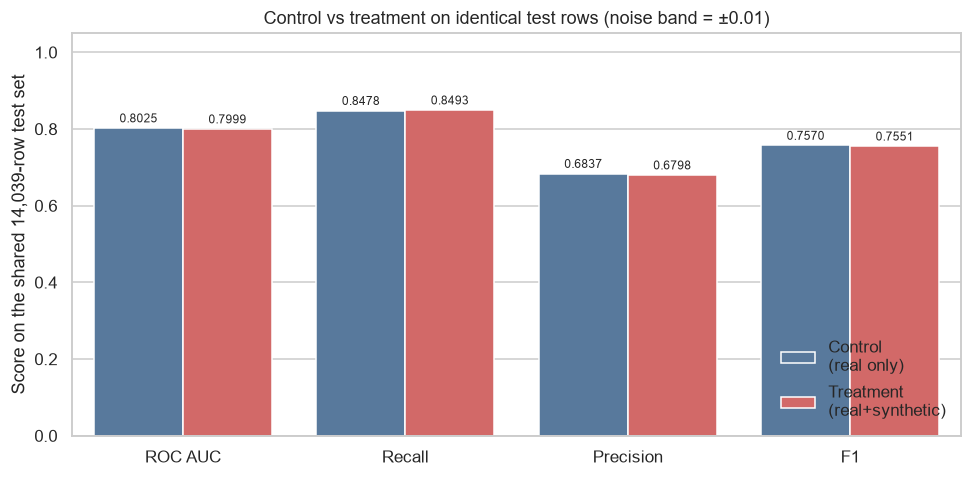

In [42]:
# Human-readable names for the two models
MODEL_LABELS = {
    "Control 128k (real only)":        "Control\n(real only)",
    "Treatment 200k (real+synthetic)": "Treatment\n(real+synthetic)",
}
MODEL_PALETTE = {
    "Control\n(real only)":        "#4C78A8",
    "Treatment\n(real+synthetic)": "#E45756",
}

# Reshape results to long form (one row per model × metric)
plot_df = results.melt(
    id_vars="Model",
    value_vars=["ROC_AUC", "Recall", "Precision", "F1"],
    var_name="Metric", value_name="Score",
)
plot_df["Model"]  = plot_df["Model"].map(MODEL_LABELS)
plot_df["Metric"] = plot_df["Metric"].str.replace("_", " ")

# Sanity check before plotting
print("plot_df shape:", plot_df.shape)
print("models:", plot_df["Model"].unique().tolist())
print("metrics:", plot_df["Metric"].unique().tolist())

# Grouped bar chart
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model",
            palette=MODEL_PALETTE, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=2, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("Score on the shared 14,039-row test set")
ax.set_title(f"Control vs treatment on identical test rows (noise band = ±{NOISE_BAND})")
ax.legend(loc="lower right", frameon=False, title=None)
plt.tight_layout()
plt.show()

## 7. Verdict

**Every metric sits inside the ±0.01 noise band.** The treatment is not better than the control on any of AUC, recall, precision or F1, and it is very slightly worse on three of the four (AUC −0.0026, precision −0.0039, F1 −0.0018). Recall is +0.0014, well inside noise.

**Answer to issue #3:** the 71,922 synthetic diabetes rows **did not materially change** holdout performance on this split. The 200k model's headline result (AUC ≈ 0.800, recall ≈ 0.849) therefore reflects **class weighting and the 100,000 real no-diabetes rows**, not synthetic augmentation. The synthetic rows are not where the lift comes from, and the report should say so directly. This is a valid, honest finding.

**What this does NOT establish:**

- **One synthetic process only.** 07 used a specific `generate_synthetic` configuration. This control tests whether **that** configuration helps. It says nothing about other synthetic approaches.
- **One split.** A different seed or a different real 100k sample could change the size of ΔAUC. This is a single-draw estimate, not a confidence interval.
- **Threshold rule drives recall.** Recall is measured at the OOF-85% operating point. If both models land on a similar threshold, recall will match even when underlying probabilities differ slightly. AUC is the safer metric for "did the ranking change".
- **No `control − 70k` attribution here.** Comparing the control against the 70k model would attribute the real-data + class-weighting effect, but the 70k model was trained on a different real pool with a different seed. That comparison belongs in `08_model_comparison` alongside the feature-parity fix, not in this notebook.

plot_df shape: (8, 3)
models: ['Control\n(real only)', 'Treatment\n(real+synthetic)']
metrics: ['ROC AUC', 'Recall', 'Precision', 'F1']


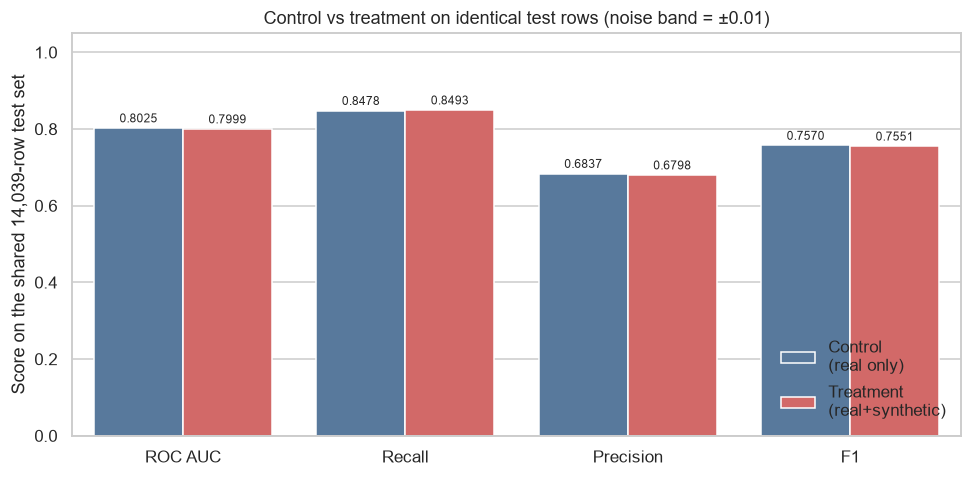

In [ ]:
# Human-readable names for the two models
MODEL_LABELS = {
    "Control 128k (real only)":        "Control\n(real only)",
    "Treatment 200k (real+synthetic)": "Treatment\n(real+synthetic)",
}
MODEL_PALETTE = {
    "Control\n(real only)":        "#4C78A8",
    "Treatment\n(real+synthetic)": "#E45756",
}

# Reshape results to long form (one row per model × metric)
plot_df = results.melt(
    id_vars="Model",
    value_vars=["ROC_AUC", "Recall", "Precision", "F1"],
    var_name="Metric", value_name="Score",
)
plot_df["Model"]  = plot_df["Model"].map(MODEL_LABELS)
plot_df["Metric"] = plot_df["Metric"].str.replace("_", " ")

# Sanity check before plotting
print("plot_df shape:", plot_df.shape)
print("models:", plot_df["Model"].unique().tolist())
print("metrics:", plot_df["Metric"].unique().tolist())

# Grouped bar chart
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model",
            palette=MODEL_PALETTE, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=2, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("Score on the shared 14,039-row test set")
ax.set_title(f"Control vs treatment on identical test rows (noise band = ±{NOISE_BAND})")
ax.legend(loc="lower right", frameon=False, title=None)
plt.tight_layout()
plt.show()

## 7. Verdict

**Every metric sits inside the ±0.01 noise band.** The treatment is not better than the control on any of AUC, recall, precision or F1, and it is very slightly worse on three of the four (AUC −0.0026, precision −0.0039, F1 −0.0018). Recall is +0.0014, well inside noise.

**Answer to issue #3:** the 71,922 synthetic diabetes rows **did not materially change** holdout performance on this split. The 200k model's headline result (AUC ≈ 0.800, recall ≈ 0.849) therefore reflects **class weighting and the 100,000 real no-diabetes rows**, not synthetic augmentation. The synthetic rows are not where the lift comes from, and the report should say so directly. This is a valid, honest finding.

**What this does NOT establish:**

- **One synthetic process only.** 07 used a specific `generate_synthetic` configuration. This control tests whether **that** configuration helps. It says nothing about other synthetic approaches.
- **One split.** A different seed or a different real 100k sample could change the size of ΔAUC. This is a single-draw estimate, not a confidence interval.
- **Threshold rule drives recall.** Recall is measured at the OOF-85% operating point. If both models land on a similar threshold, recall will match even when underlying probabilities differ slightly. AUC is the safer metric for "did the ranking change".
- **No `control − 70k` attribution here.** Comparing the control against the 70k model would attribute the real-data + class-weighting effect, but the 70k model was trained on a different real pool with a different seed. That comparison belongs in `08_model_comparison` alongside the feature-parity fix, not in this notebook.

In [43]:
# Final verdict table, one row per metric, with interpretation computed from NOISE_BAND
verdict = pd.DataFrame({
    "Metric":    ["ROC AUC", "Recall", "Precision", "F1"],
    "Control":   [results.loc[0, "ROC_AUC"],   results.loc[0, "Recall"],
                  results.loc[0, "Precision"], results.loc[0, "F1"]],
    "Treatment": [results.loc[1, "ROC_AUC"],   results.loc[1, "Recall"],
                  results.loc[1, "Precision"], results.loc[1, "F1"]],
})
verdict["Δ (T − C)"] = verdict["Treatment"] - verdict["Control"]
verdict["Verdict"]   = np.where(
    verdict["Δ (T − C)"].abs() < NOISE_BAND,
    "Within noise — synthetic did not change this metric",
    "Real difference — see sign of Δ",
)

display(
    verdict.style
           .hide(axis="index")
           .set_properties(**{"text-align": "left"})
           .format({"Control": "{:.4f}", "Treatment": "{:.4f}", "Δ (T − C)": "{:+.4f}"})
)

Metric,Control,Treatment,Δ (T − C),Verdict
ROC AUC,0.8025,0.7999,-0.0026,Within noise — synthetic did not change this metric
Recall,0.8478,0.8493,+0.0014,Within noise — synthetic did not change this metric
Precision,0.6837,0.6798,-0.0039,Within noise — synthetic did not change this metric
F1,0.7570,0.7551,-0.0018,Within noise — synthetic did not change this metric


## 8. Summary

We built a 128k control set (same real rows as the 200k model, synthetic rows removed) and scored it against the 200k treatment on the same 14,039 test rows. All metric differences are within the ±0.01 noise band (ROC AUC −0.0026, recall +0.0014, precision −0.0039, F1 −0.0018).

**Conclusion:** The 71,922 synthetic rows did not help. The 200k model's performance comes from class weighting and the extra real no-diabetes rows, not synthetic data.

**Limitation:** One synthetic process, one split. The result is a single-draw estimate, not a confidence interval.